# Análisis de Resultados

Juan José H. Beltrán 𝄽 Ph.D. in Computer Sciences

In [1]:
# Start working from the root directory of the repository
import os
os.chdir('../')

In [2]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

In [3]:
df_logs = pd.read_csv('solutions/logs.csv')
df_optimals = pd.read_csv('solutions/optimals.csv')
df_registry = pd.read_csv('instances/registry.csv')

In [4]:
df_registry.merge(df_optimals[pd.notna(df_optimals['makespan'])], how='inner', on='instance').groupby(['source', 'classification'])['instance'].count().reset_index()

,source,classification,instance
0,fisher-thompson1963,easy,2
1,fisher-thompson1963,hard,1
2,generated,easy,20
3,generated,toy,5
4,lawrence1984,easy,10
5,lawrence1984,hard,15
6,lawrence1984,medium,15


In [5]:
df_registry['ops'] = df_registry['jobs'] * df_registry['machines']

In [6]:
df_proc_logs = df_logs.merge(df_optimals[['instance', 'makespan']].rename({'makespan': 'optimal_makespan'}, axis=1), how='left', on='instance')
df_proc_logs['gap'] = (df_proc_logs['makespan'] - df_proc_logs['optimal_makespan'])/df_proc_logs['optimal_makespan']
df_proc_logs = df_proc_logs.merge(df_registry[['instance', 'horizon', 'jobs', 'machines']], how='left', on='instance')
df_proc_logs['ops'] = df_proc_logs['jobs'] * df_proc_logs['machines']
df_proc_logs['solution_found'] = (df_proc_logs['makespan'] != df_proc_logs['horizon']).astype(int)

In [7]:
df_proc_logs = df_proc_logs[pd.notna(df_proc_logs['gap'])]

In [8]:
df_proc_logs['runtime'] = df_proc_logs.apply(lambda x: 60 if x['runtime'] > 60 and x['algorithm'] != 'milp' else x['runtime'], axis=1)

In [9]:
df_proc_logs

,timestamp,algorithm,instance,time_limit,seed,makespan,runtime,expanded_nodes,weight,heuristic,...,initial_temp,cooling_rate,min_temp,optimal_makespan,gap,horizon,jobs,machines,ops,solution_found
0,2026-10-14 18:49:00,uninformed-dfs,ft06,60.0,NaN,112,60.000000,44366054.0,NaN,NaN,...,NaN,NaN,NaN,55.0,1.036364,197,6,6,36,1
1,2026-10-14 18:50:00,uninformed-dfs,ft10,60.0,NaN,2834,60.000000,30847875.0,NaN,NaN,...,NaN,NaN,NaN,930.0,2.047312,5109,10,10,100,1
2,2026-10-14 18:51:00,uninformed-dfs,ft20,60.0,NaN,3010,60.000000,17313245.0,NaN,NaN,...,NaN,NaN,NaN,1165.0,1.583691,5109,20,5,100,1
3,2026-10-14 18:52:00,uninformed-dfs,jb01,60.0,NaN,320,0.035835,26694.0,NaN,NaN,...,NaN,NaN,NaN,320.0,0.000000,624,3,4,12,1
4,2026-10-14 18:52:00,uninformed-dfs,jb02,60.0,NaN,279,0.048901,40072.0,NaN,NaN,...,NaN,NaN,NaN,279.0,0.000000,543,3,4,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1182,2026-10-21 18:30:11,milp,jb21,NaN,NaN,533,1.967504,NaN,NaN,NaN,...,NaN,NaN,NaN,533.0,0.000000,2345,7,7,49,1
1183,2026-10-21 18:32:40,milp,jb22,NaN,NaN,771,1.328919,NaN,NaN,NaN,...,NaN,NaN,NaN,771.0,0.000000,3115,6,10,60,1
1184,2026-10-21 18:34:21,milp,jb23,NaN,NaN,667,12.501041,NaN,NaN,NaN,...,NaN,NaN,NaN,667.0,0.000000,3400,8,8,64,1
1185,2026-10-21 18:41:01,milp,jb24,NaN,NaN,658,61.540673,NaN,NaN,NaN,...,NaN,NaN,NaN,658.0,0.000000,3127,9,7,63,1


In [21]:
aux = df_proc_logs[(df_proc_logs['algorithm'] == 'heuristic-wa') & (df_proc_logs['weight'] == 100) & (df_proc_logs['solution_found'] == 1)] # & (df_proc_logs['runtime'] < 60)]
aux

,timestamp,algorithm,instance,time_limit,seed,makespan,runtime,expanded_nodes,weight,heuristic,...,initial_temp,cooling_rate,min_temp,optimal_makespan,gap,horizon,jobs,machines,ops,solution_found
415,2026-10-16 10:00:53,heuristic-wa,ft06,60.0,NaN,82,60.000000,7421579.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,55.0,0.490909,197,6,6,36,1
418,2026-10-16 10:04:08,heuristic-wa,jb01,60.0,NaN,320,0.110288,26539.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,320.0,0.000000,624,3,4,12,1
419,2026-10-16 10:04:08,heuristic-wa,jb02,60.0,NaN,279,0.161761,39529.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,279.0,0.000000,543,3,4,12,1
420,2026-10-16 10:04:09,heuristic-wa,jb03,60.0,NaN,459,60.000000,9542425.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,398.0,0.153266,1202,5,4,20,1
421,2026-10-16 10:05:10,heuristic-wa,jb04,60.0,NaN,318,0.121758,30176.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,318.0,0.000000,653,3,4,12,1
422,2026-10-16 10:05:10,heuristic-wa,jb05,60.0,NaN,370,60.000000,11355086.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,370.0,0.000000,884,5,3,15,1
424,2026-10-16 10:07:44,heuristic-wa,jb07,60.0,NaN,921,60.000000,3774269.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,678.0,0.358407,3580,10,7,70,1
425,2026-10-16 10:08:45,heuristic-wa,jb08,60.0,NaN,873,60.000000,6197116.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,600.0,0.455000,2025,6,7,42,1
427,2026-10-16 10:10:53,heuristic-wa,jb10,60.0,NaN,845,60.000000,2952833.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,473.0,0.786469,1717,6,7,42,1
434,2026-10-16 10:19:38,heuristic-wa,jb17,60.0,NaN,996,60.000000,6836931.0,100.0,combined_bound_heuristic,...,NaN,NaN,NaN,619.0,0.609047,2361,6,8,48,1


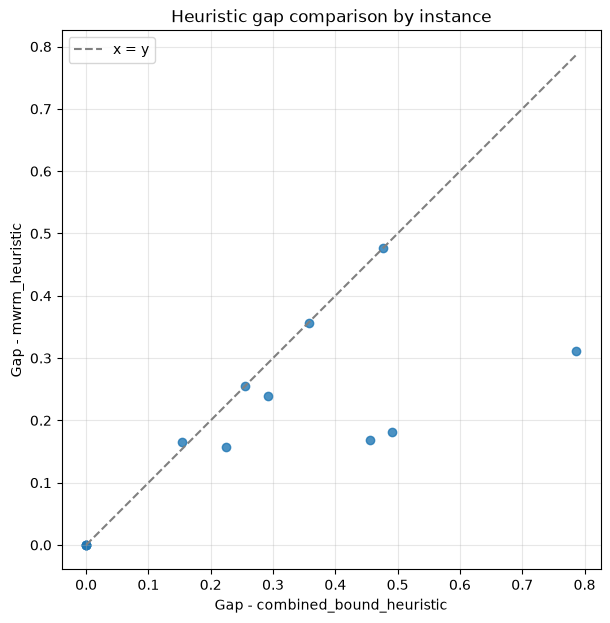

In [22]:
heuristic_gaps = (
    aux.loc[
        aux["heuristic"].isin(["combined_bound_heuristic", "mwrm_heuristic"]),
        ["instance", "heuristic", "gap"],
    ]
    .pivot(index="instance", columns="heuristic", values="gap")
    .dropna(subset=["combined_bound_heuristic", "mwrm_heuristic"])
)

x = heuristic_gaps["combined_bound_heuristic"]
y = heuristic_gaps["mwrm_heuristic"]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x, y, alpha=0.8)

plot_min = min(x.min(), y.min())
plot_max = max(x.max(), y.max())
ax.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="gray", label="x = y")

ax.set_xlabel("Gap - combined_bound_heuristic")
ax.set_ylabel("Gap - mwrm_heuristic")
ax.set_title("Heuristic gap comparison by instance")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [23]:
aux2 = df_proc_logs[(df_proc_logs['algorithm'] == 'heuristic-bs') & (df_proc_logs['solution_found'] == 1) & (df_proc_logs['runtime'] < 60)]
aux2

,timestamp,algorithm,instance,time_limit,seed,makespan,runtime,expanded_nodes,weight,heuristic,...,initial_temp,cooling_rate,min_temp,optimal_makespan,gap,horizon,jobs,machines,ops,solution_found
166,2026-10-15 21:32:23,heuristic-bs,ft06,60.0,NaN,86,1.307531,33259.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,55.0,0.563636,197,6,6,36,1
167,2026-10-15 21:32:24,heuristic-bs,ft10,60.0,NaN,1738,17.124829,98111.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,930.0,0.868817,5109,10,10,100,1
168,2026-10-15 21:32:42,heuristic-bs,ft20,60.0,NaN,1710,54.293228,98421.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,1165.0,0.467811,5109,20,5,100,1
169,2026-10-15 21:33:36,heuristic-bs,jb01,60.0,NaN,320,0.113444,7051.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,320.0,0.000000,624,3,4,12,1
170,2026-10-15 21:33:36,heuristic-bs,jb02,60.0,NaN,295,0.089330,7051.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,279.0,0.057348,543,3,4,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,2026-10-16 08:37:46,heuristic-bs,la36,60.0,NaN,4519,9.269457,22416.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,1268.0,2.563880,11739,15,15,225,1
411,2026-10-16 08:37:56,heuristic-bs,la37,60.0,NaN,4066,10.767489,22416.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,1397.0,1.910523,12569,15,15,225,1
412,2026-10-16 08:38:06,heuristic-bs,la38,60.0,NaN,3755,9.585369,22416.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,1196.0,2.139632,11217,15,15,225,1
413,2026-10-16 08:38:16,heuristic-bs,la39,60.0,NaN,3210,9.783556,22416.0,NaN,combined_bound_heuristic,...,NaN,NaN,NaN,1233.0,1.603406,11554,15,15,225,1


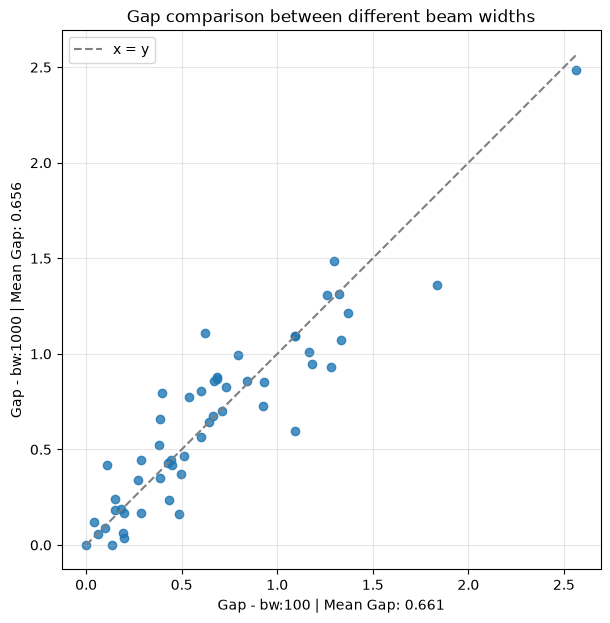

In [34]:
bs_gaps = (
    aux2.loc[
        aux2["beam_width"].isin([100, 1000]),
        ["instance", "beam_width", "gap"],
    ]
    .pivot(index="instance", columns="beam_width", values="gap")
    .dropna(subset=[100, 1000])
)

x = bs_gaps[100]
y = bs_gaps[1000]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x, y, alpha=0.8)

plot_min = min(x.min(), y.min())
plot_max = max(x.max(), y.max())
ax.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="gray", label="x = y")

ax.set_xlabel(f"Gap - bw:100 | Mean Gap: {np.mean(x):.3f}")
ax.set_ylabel(f"Gap - bw:1000 | Mean Gap: {np.mean(y):.3f}")
ax.set_title("Gap comparison between different beam widths")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [ ]:
experiment_ids = ['algorithm', 'seed', 'weight', 'heuristic', 'beam_width', 'neighborhood', 'cooling_rate']

In [ ]:
df_grpd_logs = df_proc_logs.groupby(experiment_ids, dropna=False).agg(
    num_instances = ('instance', 'count'),
    mean_runtime=('runtime', 'mean'),
    mean_gap=('gap', 'mean'),
    instances_with_solution = ('solution_found', 'sum')
).reset_index()

## General Results Table

In [ ]:
classifications = ['toy', 'easy', 'medium', 'hard']

# Ensure classification is available in df_proc_logs.
if 'classification' not in df_proc_logs.columns:
    df_proc_logs = df_proc_logs.merge(
        df_registry[['instance', 'classification']],
        on='instance',
        how='left',
    )

# Number of distinct instances in each classification, used as the rate denominator.
instances_per_classification = (
    df_proc_logs.groupby('classification')['instance']
    .nunique()
)

results = []

for _, experiment_logs in df_proc_logs.groupby(
    experiment_ids,
    dropna=False,
    sort=False,
):
    first_run = experiment_logs.iloc[0]

    # Exclude the algorithm name and unset parameters from the parameter dictionary.
    parameters = {
        column: first_run[column]
        for column in experiment_ids
        if column != 'algorithm' and pd.notna(first_run[column])
    }

    result = {
        'algorithm': first_run['algorithm'],
        'parameters': parameters,
    }

    for classification in classifications:
        class_logs = experiment_logs.loc[
            experiment_logs['classification'] == classification
        ]

        total_instances = instances_per_classification.get(classification, 0)

        result[f'{classification}_mean_gap'] = class_logs['gap'].mean()
        result[f'{classification}_mean_runtime'] = class_logs['runtime'].mean()

        # Count distinct instances with a solution, avoiding duplicate-run overcounts.
        solved_instances = (
            class_logs.groupby('instance')['solution_found']
            .max()
            .sum()
        )
        # result[f'{classification}_solved_instances'] = int(solved_instances)

        result[f'{classification}_solved_rate'] = (
            solved_instances / total_instances if total_instances else float('nan')
        )

    for classification in ['all']:
            class_logs = experiment_logs    
            total_instances = len(experiment_logs)
    
            result[f'{classification}_mean_gap'] = class_logs['gap'].mean()
            result[f'{classification}_mean_runtime'] = class_logs['runtime'].mean()
    
            # Count distinct instances with a solution, avoiding duplicate-run overcounts.
            solved_instances = (
                class_logs.groupby('instance')['solution_found']
                .max()
                .sum()
            )
            # result[f'{classification}_solved_instances'] = int(solved_instances)
    
            result[f'{classification}_solved_rate'] = (
                solved_instances / total_instances if total_instances else float('nan')
            )

    results.append(result)

df_experiment_results = pd.DataFrame(results)

In [ ]:
df_experiment_results.to_csv('analysis/results/results.csv')
df_experiment_results = df_experiment_results.sort_values(['algorithm']).reset_index(drop=True)

In [ ]:
df_experiment_results

,algorithm,parameters,toy_mean_gap,toy_mean_runtime,toy_solved_rate,easy_mean_gap,easy_mean_runtime,easy_solved_rate,medium_mean_gap,medium_mean_runtime,medium_solved_rate,hard_mean_gap,hard_mean_runtime,hard_solved_rate,all_mean_gap,all_mean_runtime,all_solved_rate
0,heuristic-bs,"{'heuristic': 'combined_bound_heuristic', 'bea...",0.092244,0.273813,1.0,0.829566,8.373921,1.00000,2.691770,38.519829,0.733333,4.823025,52.112934,0.375,2.125769,24.719690,0.794118
1,heuristic-bs,"{'heuristic': 'combined_bound_heuristic', 'bea...",0.133138,0.028542,1.0,0.795329,0.906364,1.00000,1.058160,5.920075,1.000000,0.425975,19.841825,1.000,0.717709,6.403187,1.000000
2,heuristic-wa,"{'weight': 1.0, 'heuristic': 'combined_bound_h...",0.404020,24.110288,0.8,3.799467,60.000000,0.00000,6.156506,60.000000,0.000000,6.025479,60.000000,0.000,4.593504,57.361051,0.058824
3,heuristic-wa,"{'weight': 100.0, 'heuristic': 'combined_bound...",0.030653,24.078761,1.0,3.076485,60.000000,0.28125,5.941294,60.000000,0.066667,6.025479,60.000000,0.000,4.178351,57.358732,0.220588
4,heuristic-wa,"{'weight': 100.0, 'heuristic': 'mwrm_heuristic'}",0.033166,24.100279,1.0,2.676977,60.000000,0.37500,5.523634,60.000000,0.200000,6.025479,60.000000,0.000,3.898401,57.360315,0.294118
5,heuristic-wa,"{'weight': 1.0, 'heuristic': 'mwrm_heuristic'}",0.404020,24.128112,0.8,3.799467,60.000000,0.00000,6.156506,60.000000,0.000000,6.025479,60.000000,0.000,4.593504,57.362361,0.058824
6,local-sa,"{'seed': 42.0, 'neighborhood': 'shift_reinsert...",0.000000,0.023338,1.0,0.044545,0.050429,1.00000,0.103634,0.095812,1.000000,0.075672,0.120216,1.000,0.061628,0.074868,1.000000
7,local-sa,"{'seed': 42.0, 'neighborhood': 'shift_reinsert...",0.000000,0.067245,1.0,0.026342,0.214554,1.00000,0.057213,0.443868,1.000000,0.023298,0.564969,1.000,0.030499,0.336757,1.000000
8,local-sa,"{'seed': 42.0, 'neighborhood': 'random_swap_op...",0.000000,0.068018,1.0,0.024891,0.216286,1.00000,0.065868,0.440173,1.000000,0.029664,0.561567,1.000,0.033223,0.336014,1.000000
9,local-sa,"{'seed': 42.0, 'neighborhood': 'random_swap_op...",0.000000,0.014804,1.0,0.044990,0.047412,1.00000,0.113206,0.095400,1.000000,0.103978,0.120724,1.000,0.070609,0.072850,1.000000


# Análisis

In [ ]:
df_proc_logs = df_proc_logs[df_proc_logs['solution_found'] == 1]

In [ ]:
def _experiment_color_key(experiment):
    """Build a stable color key for Python and NumPy scalar values."""
    key = []
    for column in experiment_ids:
        value = experiment[column]
        if isinstance(value, np.generic):
            value = value.item()
        key.append((column, repr(value)))
    return tuple(key)


_experiment_colors = {}
_experiment_color_palette = plt.get_cmap('turbo')
for index, experiment in enumerate(df_grpd_logs[experiment_ids].to_dict('records')):
    color_key = _experiment_color_key(experiment)
    _experiment_colors[color_key] = _experiment_color_palette(
        index / max(len(df_grpd_logs) - 1, 1)
    )

## Plot the evolution of the metrics across different problem sizes

In [ ]:
def plot_experiment_generalization(experiments):
    """Plot metrics by instance size for rows from df_experiment_results."""
    if isinstance(experiments, pd.DataFrame):
        experiment_records = experiments.to_dict('records')
    elif isinstance(experiments, (pd.Series, dict)):
        experiment_records = [experiments]
    else:
        experiment_records = list(experiments)

    classifications = ['toy', 'easy', 'medium', 'hard']
    metrics = (
        ('mean_gap', 'Mean relative gap'),
        ('mean_runtime', 'Mean runtime (seconds)'),
        ('solved_rate', 'Solved instances rate'),
    )
    metric_columns = [
        f'{classification}_{metric}'
        for classification in classifications
        for metric, _ in metrics
    ]

    normalized_experiments = []
    for experiment in experiment_records:
        if isinstance(experiment, pd.Series):
            experiment = experiment.to_dict()
        if not isinstance(experiment, dict):
            raise TypeError('Each experiment must be a dict or pandas Series.')

        missing_fields = [
            field for field in ('algorithm', 'parameters')
            if field not in experiment
        ]
        missing_fields.extend(
            column for column in metric_columns if column not in experiment
        )
        if missing_fields:
            raise ValueError(f'Experiment is missing fields: {missing_fields}')
        if not isinstance(experiment['parameters'], dict):
            raise ValueError('Experiment parameters must be a dictionary.')
        normalized_experiments.append(experiment)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
    for experiment in normalized_experiments:
        parameters = experiment['parameters']
        identity = {
            column: experiment['algorithm'] if column == 'algorithm'
            else parameters.get(column, np.nan)
            for column in experiment_ids
        }
        color_key = _experiment_color_key(identity)
        if color_key not in _experiment_colors:
            color_index = len(_experiment_colors)
            _experiment_colors[color_key] = _experiment_color_palette(
                color_index / max(color_index + 1, 1)
            )

        label_parts = [str(experiment['algorithm'])]
        label_parts.extend(
            f'{column}: {parameters[column]}'
            for column in experiment_ids
            if column != 'algorithm' and column in parameters
            and not pd.isna(parameters[column])
        )
        label = '; '.join(label_parts)

        for ax, (metric, ylabel) in zip(axes, metrics):
            values = [
                experiment[f'{classification}_{metric}']
                for classification in classifications
            ]
            ax.plot(
                classifications, values, marker='o',
                color=_experiment_colors[color_key], label=label,
            )
            ax.set_title(ylabel)
            ax.set_xlabel('Instance size')
            ax.set_ylabel(ylabel)
            ax.grid(True, linestyle='--', alpha=0.3)

    axes[2].set_ylim(-0.05, 1.05)
    if normalized_experiments:
        handles, legend_labels = axes[0].get_legend_handles_labels()
        fig.legend(
            handles, legend_labels, title='Experiment',
            loc='upper center', bbox_to_anchor=(0.5, 1.07),
            ncol=min(len(legend_labels), 3),
            fontsize = 'small'
        )

    # fig.suptitle('Generalization across instance sizes')
    bottom = 0.12 if normalized_experiments else 0
    fig.tight_layout(rect=(0, bottom, 1, 0.92))
    return fig, axes

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: title={'center': 'Mean relative gap'}, xlabel='Instance size', ylabel='Mean relative gap'>,
        <Axes: title={'center': 'Mean runtime (seconds)'}, xlabel='Instance size', ylabel='Mean runtime (seconds)'>,
        <Axes: title={'center': 'Solved instances rate'}, xlabel='Instance size', ylabel='Solved instances rate'>],
       dtype=object))

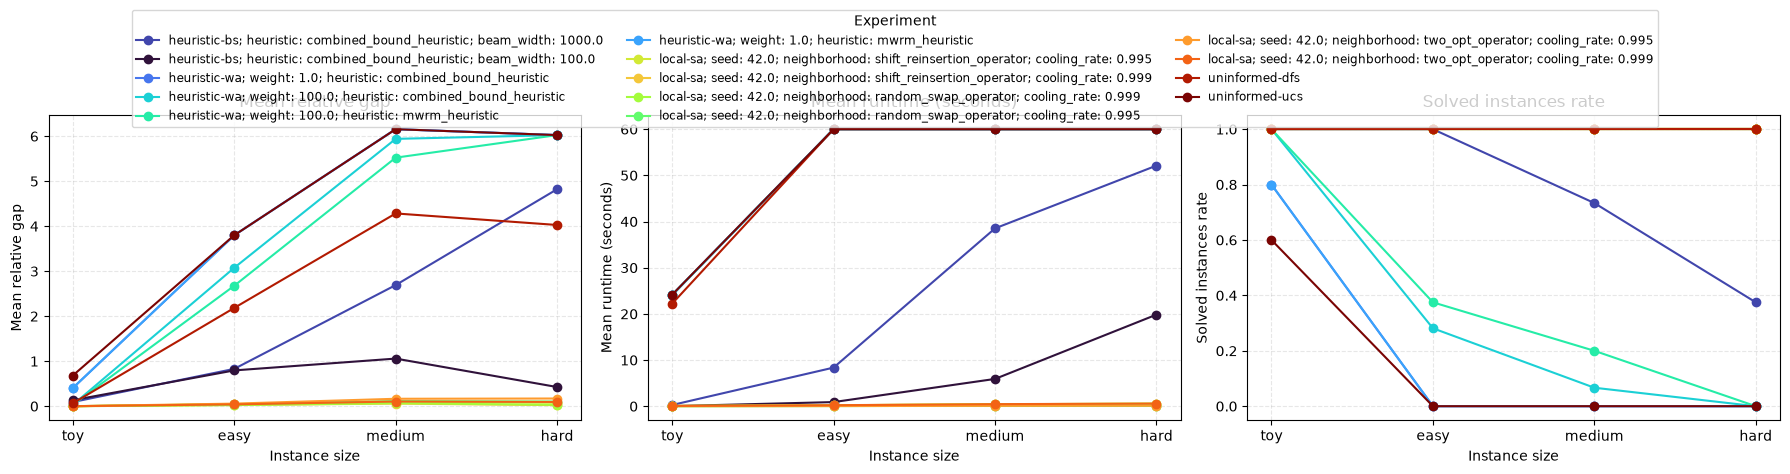

In [ ]:
# Compare two heuristic-wa experiments, each run across all 83 instances.
experiments = df_experiment_results[df_experiment_results.index.isin([2, 3, 4, 5])]

plot_experiment_generalization(experiments.to_dict('records'))

## Overall performance of each method per classification

In [58]:
def plot_experiment_results(df_experiment_results):
    """Compare experiment performance across instance classifications."""
    classifications = ['toy', 'easy', 'medium', 'hard', 'all']
    metric_columns = [
        f'{classification}_{metric}'
        for classification in classifications
        for metric in ('solved_rate', 'mean_gap', 'mean_runtime')
    ]
    required_columns = ['algorithm', 'parameters', *metric_columns]
    missing_columns = [
        column for column in required_columns
        if column not in df_experiment_results.columns
    ]
    if missing_columns:
        raise ValueError(f'Experiment results are missing columns: {missing_columns}')

    runtime_columns = [f'{category}_mean_runtime' for category in classifications]
    runtimes = df_experiment_results[runtime_columns].apply(pd.to_numeric, errors='coerce')
    if (runtimes < 0).any().any():
        raise ValueError('Mean runtime must be non-negative.')
    transformed_runtimes = np.log10(1 + runtimes)
    max_transformed_runtime = transformed_runtimes.max().max()
    min_marker_size = 200
    max_marker_size = 1000

    fig, axes = plt.subplots(1, len(classifications), figsize=(25, 5), sharey=True)
    legend_handles = []
    legend_labels = []

    for _, experiment in df_experiment_results.iterrows():
        if not isinstance(experiment['parameters'], dict):
            raise ValueError('Experiment parameters must be a dictionary.')

        identity = {
            column: experiment['algorithm'] if column == 'algorithm'
            else experiment['parameters'].get(column, np.nan)
            for column in experiment_ids
        }
        color_key = _experiment_color_key(identity)
        if color_key not in _experiment_colors:
            color_index = len(_experiment_colors)
            _experiment_colors[color_key] = _experiment_color_palette(
                color_index / max(color_index + 1, 1)
            )

        label_parts = [str(experiment['algorithm'])]
        label_parts.extend(
            f'{column}: {experiment["parameters"][column]}'
            for column in experiment_ids
            if column != 'algorithm' and column in experiment['parameters']
            and not pd.isna(experiment['parameters'][column])
        )
        label = '; '.join(label_parts)

        for ax, category in zip(axes, classifications):
            solved_rate = experiment[f'{category}_solved_rate']
            mean_gap = experiment[f'{category}_mean_gap']
            mean_runtime = pd.to_numeric(
                experiment[f'{category}_mean_runtime'], errors='coerce'
            )
            if pd.isna(solved_rate) or pd.isna(mean_gap) or pd.isna(mean_runtime):
                continue
            transformed_runtime = np.log10(1 + mean_runtime)
            marker_size = (
                min_marker_size
                + (max_marker_size - min_marker_size)
                * transformed_runtime / max_transformed_runtime
                if max_transformed_runtime > 0 else min_marker_size
            )

            ax.scatter(
                solved_rate, mean_gap, s=marker_size,
                color=_experiment_colors[color_key], alpha=0.5,
                edgecolors='white', linewidths=0.5,
            )
            ax.set_yscale("log");
            if label not in legend_labels:
                legend_handles.append(ax.scatter(
                    [], [], s=100, color=_experiment_colors[color_key],
                    alpha=0.7, edgecolors='white', linewidths=0.5,
                ))
                legend_labels.append(label)

    for ax, category in zip(axes, classifications):
        ax.set_title(category.capitalize())
        ax.set_xlabel('Instances with solution found rate')
        ax.set_xlim(-0.05, 1.05)
        ax.grid(True, linestyle='--', alpha=0.4)
    axes[0].set_ylabel('Mean relative gap')
    if legend_handles:
        fig.legend(
            legend_handles, legend_labels, title='Experiment',
            loc='upper center', bbox_to_anchor=(0.5, 1.11),
            ncol=min(len(legend_labels), 4), fontsize='small',
        )
    fig.tight_layout(rect=(0, 0, 1, 0.9 if legend_handles else 1))
    return fig, axes

(<Figure size 2500x500 with 5 Axes>,
 array([<Axes: title={'center': 'Toy'}, xlabel='Instances with solution found rate', ylabel='Mean relative gap'>,
        <Axes: title={'center': 'Easy'}, xlabel='Instances with solution found rate'>,
        <Axes: title={'center': 'Medium'}, xlabel='Instances with solution found rate'>,
        <Axes: title={'center': 'Hard'}, xlabel='Instances with solution found rate'>,
        <Axes: title={'center': 'All'}, xlabel='Instances with solution found rate'>],
       dtype=object))

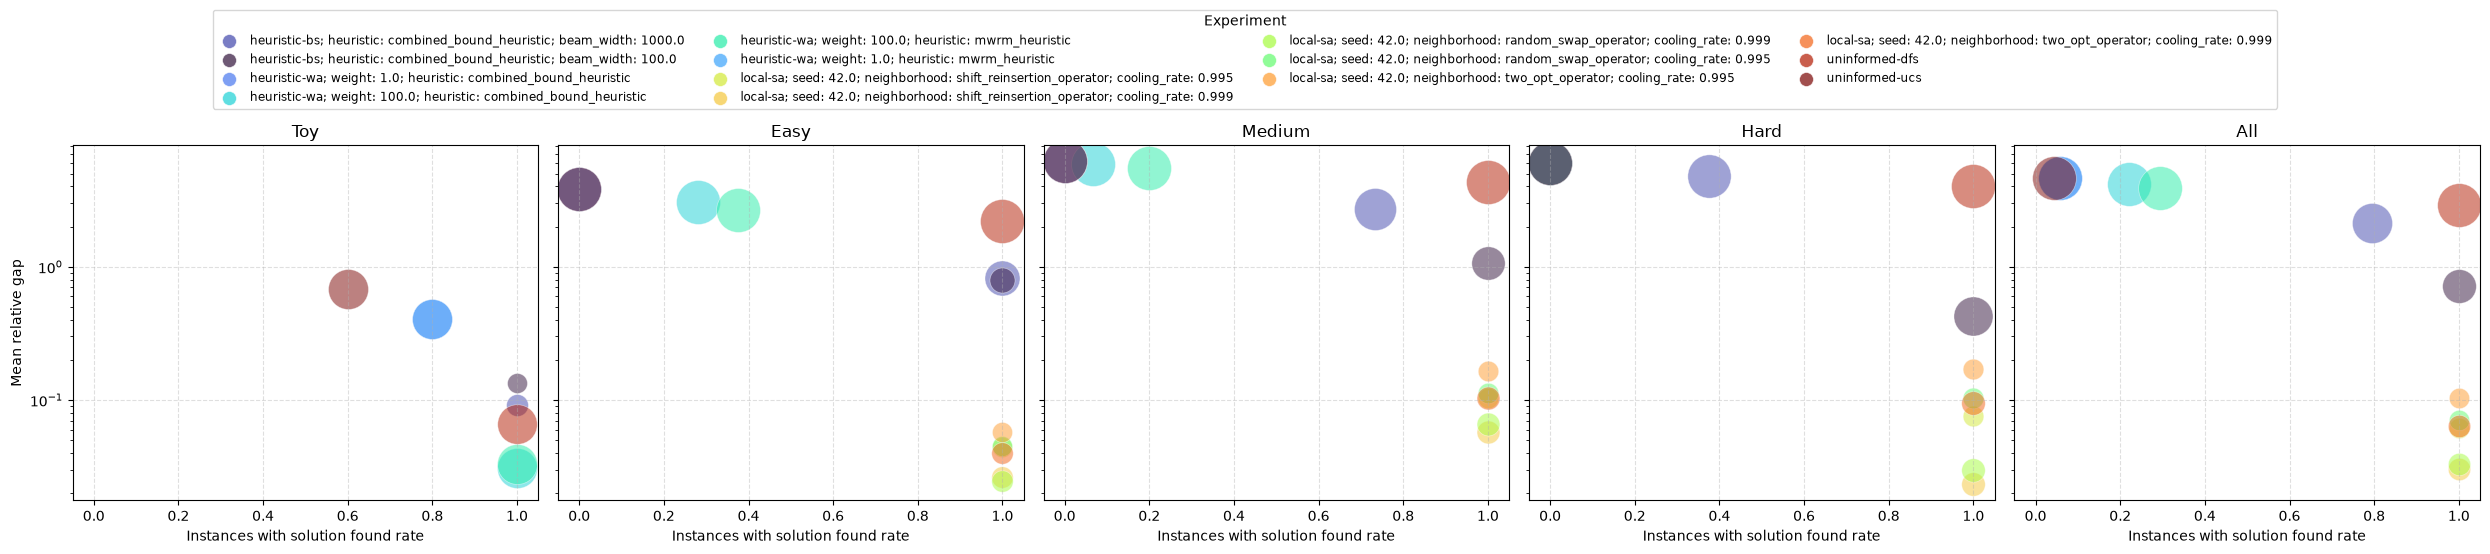

In [59]:
experiments = df_experiment_results[df_experiment_results.index.isin([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14])]

#[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14]

plot_experiment_results(experiments)

## Plot execution results

In [40]:
def plot_experiments(experiments):
    """Plot runs from df_proc_logs, colored by experiment.

    Each item should be a dict or pandas Series containing the columns in
    experiment_ids, such as a record from df_grpd_logs.
    """
    hgt = 0.5

    if isinstance(experiments, pd.DataFrame):
        experiments = experiments.to_dict('records')
    else:
        experiments = list(experiments)

    fig, ax = plt.subplots(figsize=(16, 9))

    for experiment in experiments:
        if isinstance(experiment, pd.Series):
            experiment = experiment.to_dict()

        missing_columns = [column for column in experiment_ids if column not in experiment]
        if missing_columns:
            raise ValueError(f"Experiment is missing identity columns: {missing_columns}")

        mask = pd.Series(True, index=df_proc_logs.index)
        for column in experiment_ids:
            value = experiment[column]
            if pd.isna(value):
                mask &= df_proc_logs[column].isna()
            else:
                mask &= df_proc_logs[column].eq(value)

        runs = df_proc_logs.loc[mask]
        if runs.empty:
            raise ValueError(f"No runs found for experiment: {experiment}")

        label_parts = [
            f'{column}: {experiment[column]}'
            for column in experiment_ids
            if not pd.isna(experiment[column])
        ]
        label = '; '.join(label_parts)
        color_key = tuple((column, repr(experiment[column])) for column in experiment_ids)
        if color_key not in _experiment_colors:
            color_index = len(_experiment_colors)
            _experiment_colors[color_key] = _experiment_color_palette(
                color_index / max(color_index + 1, 1)
            )

        ax.scatter(
            runs['gap'],
            runs['runtime'],
            s=runs['ops'],
            color=_experiment_colors[color_key],
            label=label,
            alpha=0.65,
            edgecolors='white',
            linewidths=0.5,
        )

    ax.set_xlabel('Relative Gap')
    ax.set_ylabel('Runtime (Seconds)')
    ax.set_title(f'Runtime vs. Relative Gap Per Execution ({len(runs[pd.notna(runs['gap'])])} solutions found)')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.text(
        0.5,
        hgt,
        'Marker area is proportional to instance operations.',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=9,
    )
    if experiments:
        ax.legend(title='Experiment', loc='lower center', bbox_to_anchor=(0.5, hgt + 0.02), ncol=2)
    fig.tight_layout()
    return ax

<Axes: title={'center': 'Runtime vs. Relative Gap Per Execution (54 solutions found)'}, xlabel='Relative Gap', ylabel='Runtime (Seconds)'>

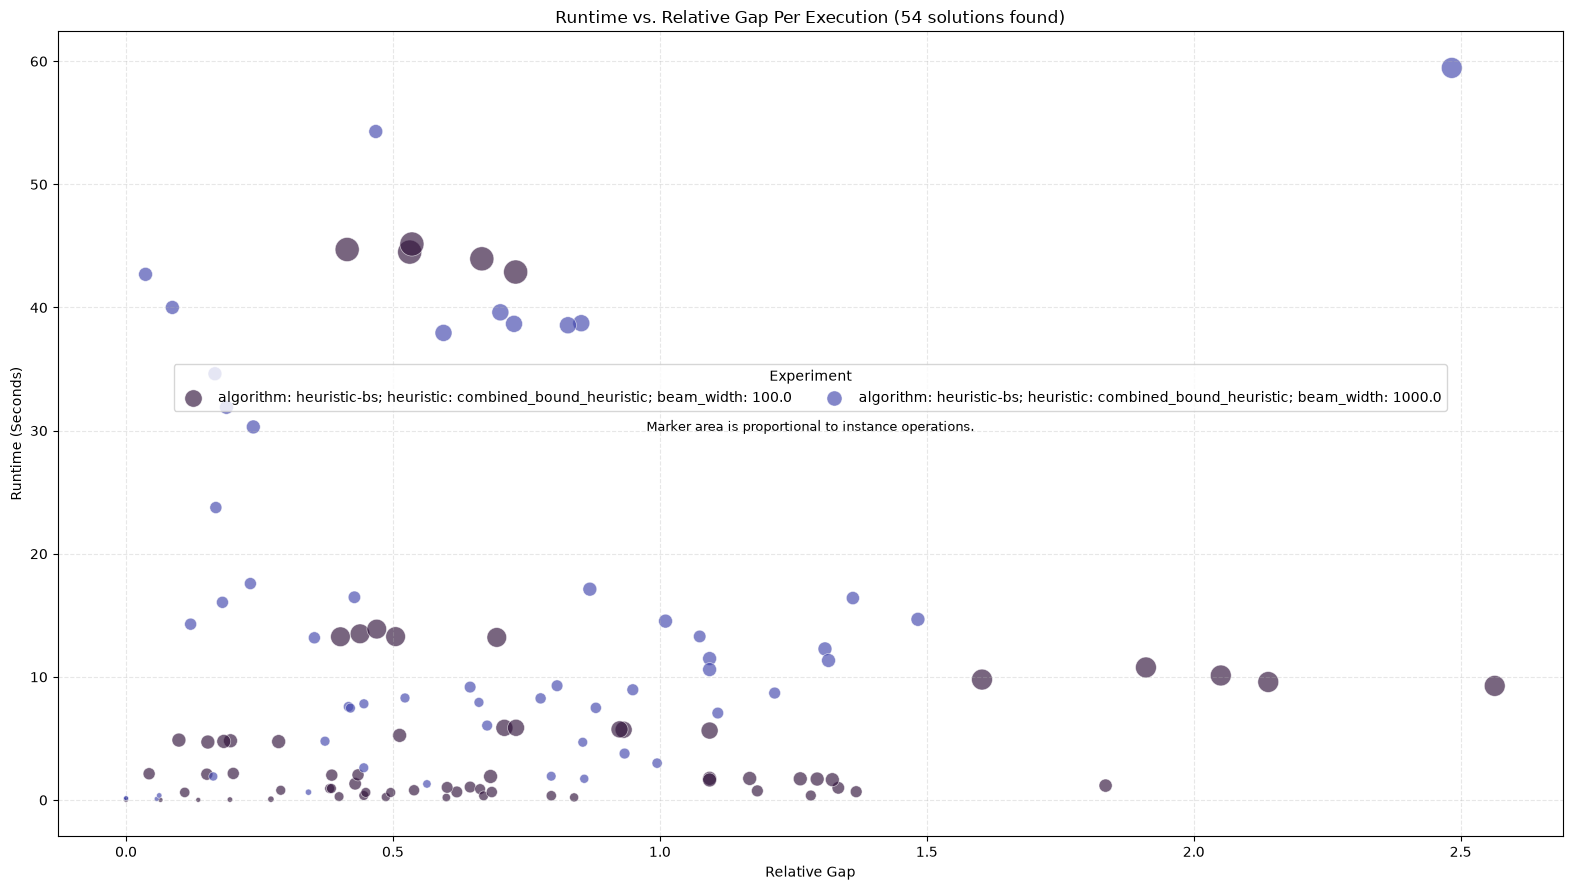

In [41]:
# Compare two heuristic-wa experiments, each run across all 83 instances.
experiments = df_grpd_logs[df_grpd_logs.index.isin([0,1])]

#assert len(experiments) == 2
#assert (experiments['num_instances'] == 83).all()

plot_experiments(experiments.to_dict('records'))

In [ ]:
# Compare two heuristic-wa experiments, each run across all 83 instances.
# experiments = df_grpd_logs.loc[
#     (df_grpd_logs['algorithm'] == 'heuristic-wa')
#     & (df_grpd_logs['weight'] == 1)
#     & df_grpd_logs['heuristic'].isin([
#         'combined_bound_heuristic',
#         'mwrm_heuristic',
#     ])
# ]

# #assert len(experiments) == 2
# #assert (experiments['num_instances'] == 83).all()

# plot_experiments(experiments.to_dict('records'))